In [1]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_absolute_percentage_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

from xgboost import XGBRegressor
import lightgbm as lgb
from catboost import CatBoostRegressor

import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
!pip install xgboost


In [2]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_absolute_percentage_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

from xgboost import XGBRegressor
import lightgbm as lgb
from catboost import CatBoostRegressor

import seaborn as sns
import matplotlib.pyplot as plt


In [4]:
import sys
print(sys.executable)


C:\Users\DEBS\anaconda3\envs\sfe_ml\python.exe


In [5]:
!where python


C:\Users\DEBS\anaconda3\envs\sfe_ml\python.exe
C:\Python313\python.exe
C:\Users\DEBS\anaconda3\python.exe
C:\Users\DEBS\AppData\Local\Programs\Python\Python311\python.exe
C:\Users\DEBS\AppData\Local\Microsoft\WindowsApps\python.exe


In [6]:
import sys
print(sys.executable)

!{sys.executable} -m pip install xgboost


C:\Users\DEBS\anaconda3\envs\sfe_ml\python.exe


In [7]:
import sys
print(sys.executable)

from xgboost import XGBRegressor
print("XGBRegressor imported OK")


C:\Users\DEBS\anaconda3\envs\sfe_ml\python.exe
XGBRegressor imported OK


In [8]:
import sys
!{sys.executable} -m pip install lightgbm catboost


In [3]:
df = pd.read_excel("Composition_SFE_Dataset_old.xlsx")

# Input: compositions, Output: SFE (can be negative)
X = df.drop(columns=["SFE"])
y = df["SFE"]

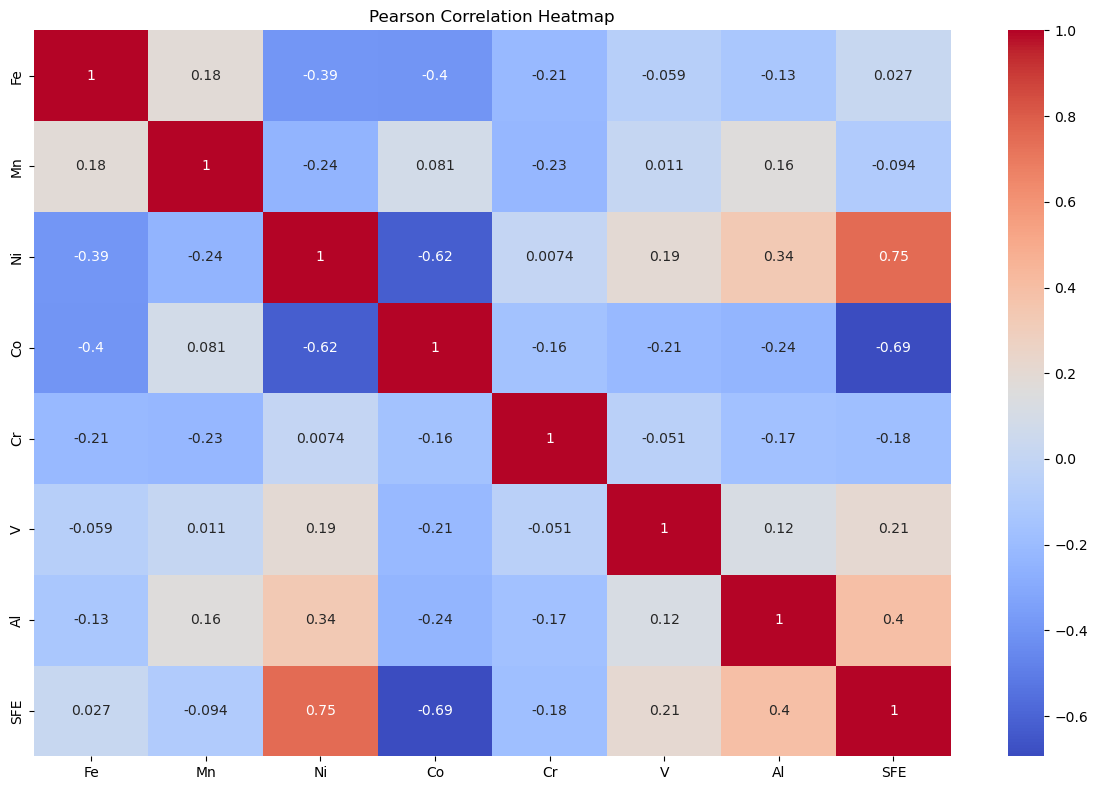

In [4]:
# Pearson correlation (no feature removal)
# ==========================
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

In [5]:
# 3. Hyperparameter grids
# ==========================
def get_param_grid_for_model(model_name):
    param_grids = {
        'lr': {
            'model__fit_intercept': [True, False],
        },
        'ridge': {
            'model__alpha': [0.1, 1.0, 10.0],
            'model__fit_intercept': [True, False],
            'model__solver': ['auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga']
        },
        'lasso': {
            'model__alpha': [0.1, 1.0, 10.0],
            'model__fit_intercept': [True, False],
            'model__positive': [False],  # True not allowed with negative targets
            'model__selection': ['cyclic', 'random']
        },
        'rf': {
            'model__n_estimators': [50, 100, 200],
            'model__max_depth': [None, 10, 20],
            'model__min_samples_split': [2, 5, 10],
            'model__min_samples_leaf': [1, 2, 4]
        },
        'gb': {
            'model__n_estimators': [50, 100, 200],
            'model__learning_rate': [0.01, 0.1, 0.2],
            'model__max_depth': [3, 5, 7],
            'model__min_samples_split': [2, 5, 10],
            'model__min_samples_leaf': [1, 2, 4]
        },
        'svr': {
            'model__C': [0.1, 1.0, 10.0],
            'model__kernel': ['linear', 'poly', 'rbf'],
            'model__gamma': ['scale', 'auto']
        },
        'knn': {
            'model__n_neighbors': [3, 5, 10],
            'model__weights': ['uniform', 'distance'],
            'model__algorithm': ['auto', 'ball_tree', 'kd_tree']
        },
        'dt': {
            'model__max_depth': [None, 5, 10, 20],
            'model__min_samples_split': [2, 5, 10],
            'model__min_samples_leaf': [1, 2, 4]
        },
        'xgb': {
            'model__n_estimators': [10, 50, 100],
            'model__learning_rate': [0.01, 0.1, 0.3],
            'model__max_depth': [3, 5],
            'model__gamma': [0, 0.1, 0.2],
            'model__reg_alpha': [0, 0.1, 0.5],
            'model__reg_lambda': [0, 1.0, 10.0],
        },
        'lgbm': {
            'model__n_estimators': [50, 100, 200],
            'model__learning_rate': [0.01, 0.1, 0.2],
            'model__max_depth': [3, 5, 7],
            'model__num_leaves': [31, 63],
            'model__min_child_samples': [20, 40],
            'model__subsample': [0.6, 0.8, 1.0],
            'model__colsample_bytree': [0.6, 0.8, 1.0]
        },
        'catboost': {
            'model__iterations': [100, 200, 500],
            'model__learning_rate': [0.01, 0.1, 0.2],
            'model__depth': [3, 5, 7]
        }
    }
    return param_grids.get(model_name, {})

In [6]:
import lightgbm as lgb
from catboost import CatBoostRegressor

In [7]:
# # Define models
# # ==========================
# models = {
#     'lr': LinearRegression(),
#     'ridge': Ridge(),
#     'lasso': Lasso(),
#     'rf': RandomForestRegressor(random_state=42),
#     'gb': GradientBoostingRegressor(random_state=42),
#     'svr': SVR(),
#     'knn': KNeighborsRegressor(),
#     'dt': DecisionTreeRegressor(random_state=42),
#     'xgb': XGBRegressor(random_state=42, n_jobs=-1),
#     'lgbm': lgb.LGBMRegressor(verbose=-1, random_state=42),
#     'catboost': CatBoostRegressor(verbose=False, random_state=42)
# }

from catboost import CatBoostRegressor

models = {
    'lr': LinearRegression(),
    'ridge': Ridge(),
    'lasso': Lasso(),
    'rf': RandomForestRegressor(random_state=42),
    'gb': GradientBoostingRegressor(random_state=42),
    'svr': SVR(),
    'knn': KNeighborsRegressor(),
    'dt': DecisionTreeRegressor(random_state=42),
    'xgb' : XGBRegressor(random_state=42, n_jobs=-1),
    'lgbm' : lgb.LGBMRegressor(verbose=-1, random_state=42),
    'catboost' : CatBoostRegressor(
        verbose=False,
        random_state=42,
        allow_writing_files=False   # 🔥 add this line
    )
}



In [8]:
# 5. Train-test split
# ==========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42
)

In [ ]:
# ==========================
best_models = {}

for name, model in models.items():
    print(f"Training model: {name}")

    pipeline = Pipeline([
        ('preprocessor', MinMaxScaler()),
        ('model', model)
    ])

    param_grid = get_param_grid_for_model(name)

    # If param_grid is empty, GridSearchCV will just fit once
    grid_search = GridSearchCV(
        pipeline,
        param_grid=param_grid,
        cv=3,
        scoring='neg_mean_squared_error',
        n_jobs=-1
    )
    grid_search.fit(X_train, y_train)

    best_models[name] = (grid_search.best_estimator_, grid_search.best_score_)

# ==========================
# 7. Select top-3 models for stacking
# ==========================
top_3_models = sorted(
    best_models.items(),
    key=lambda x: x[1][1],  # best_score_
    reverse=True
)[:3]

estimators = [(name, model) for name, (model, perf) in top_3_models]
print("Top 3 base models for stacking:", [e[0] for e in estimators])

# ==========================
# 8. Build stacked regressor
# ==========================
np.random.seed(42)

final_estimator = RandomForestRegressor(random_state=42)

final_estimator_param_grid = {
    'model__final_estimator__n_estimators': [50, 100, 200],
    'model__final_estimator__max_depth': [None, 10, 20],
    'model__final_estimator__min_samples_split': [2, 5, 10],
    'model__final_estimator__min_samples_leaf': [1, 2, 4]
}

stacked_regressor = StackingRegressor(
    estimators=estimators,
    final_estimator=final_estimator,
    passthrough=True,
    n_jobs=-1
)

stacked_model = Pipeline([
    ('preprocessor', MinMaxScaler()),
    ('model', stacked_regressor)
])

grid_search_stack = GridSearchCV(
    estimator=stacked_model,
    param_grid=final_estimator_param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_search_stack.fit(X_train, y_train)
stacked_model = grid_search_stack.best_estimator_

# ==========================
# 9. Evaluate stacked model
# ==========================
y_test_pred = stacked_model.predict(X_test)
y_train_pred = stacked_model.predict(X_train)
y_total_pred = stacked_model.predict(X)

print("\nStacked Model Performance:")
print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))
print("Overall R2:", r2_score(y, y_total_pred))
print("Train MAPE:", mean_absolute_percentage_error(y_train, y_train_pred))
print("Test MAPE:", mean_absolute_percentage_error(y_test, y_test_pred))
print("Overall MAPE:", mean_absolute_percentage_error(y, y_total_pred))

Training model: lr
Training model: ridge
Training model: lasso
Training model: rf
Training model: gb
Training model: svr
Training model: knn
Training model: dt
Training model: xgb
Training model: lgbm


In [ ]:
# ==========================
# 10. Compare individual model performance
# ==========================
model_performance_df = pd.DataFrame(
    columns=[
        "Model Name", "Train R2", "Test R2", "Overall R2",
        "Train MAPE", "Test MAPE", "Overall MAPE", "Error Variance"
    ]
)

model_namer = {
    "lr": "Linear Regression",
    "ridge": "Ridge Regression",
    "lasso": "Lasso Regression",
    "rf": "Random Forest",
    "gb": "Gradient Boosting",
    "svr": "Support Vector Regressor",
    "knn": "K-Nearest Neighbors",
    "dt": "Decision Tree",
    "xgb": "XGBoost",
    "lgbm": "LightGBM",
    "catboost": "CatBoost"
}

# ---- Base models ----
for model_name, (best_estimator, _) in best_models.items():

    # Because best_estimator is a Pipeline
    y_pred_train = best_estimator.predict(X_train)
    y_pred_test = best_estimator.predict(X_test)
    y_pred_total = best_estimator.predict(X)

    error = y_pred_total - y

    model_performance_df = pd.concat(
        [model_performance_df,
         pd.DataFrame([{
             "Model Name": model_namer.get(model_name, model_name),
             "Train R2": r2_score(y_train, y_pred_train),
             "Test R2": r2_score(y_test, y_pred_test),
             "Overall R2": r2_score(y, y_pred_total),
             "Train MAPE": mean_absolute_percentage_error(y_train, y_pred_train),
             "Test MAPE": mean_absolute_percentage_error(y_test, y_pred_test),
             "Overall MAPE": mean_absolute_percentage_error(y, y_pred_total),
             "Error Variance": error.var()
         }])],
        ignore_index=True
    )

# ---- Add stacked model ----
error_stacked = y_total_pred - y

model_performance_df = pd.concat(
    [model_performance_df,
     pd.DataFrame([{
         "Model Name": "Stacked Model",
         "Train R2": r2_score(y_train, y_train_pred),
         "Test R2": r2_score(y_test, y_test_pred),
         "Overall R2": r2_score(y, y_total_pred),
         "Train MAPE": mean_absolute_percentage_error(y_train, y_train_pred),
         "Test MAPE": mean_absolute_percentage_error(y_test, y_test_pred),
         "Overall MAPE": mean_absolute_percentage_error(y, y_total_pred),
         "Error Variance": error_stacked.var()
     }])],
    ignore_index=True
)

# Sort by best Test R2 (descending)
model_performance_df = model_performance_df.sort_values(by="Test R2", ascending=False)

print("\n========================")
print(" FULL MODEL PERFORMANCE ")
print("========================\n")
print(model_performance_df)


In [ ]:
###########Save model

In [9]:
# ============================================
# 0. IMPORTS
# ============================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_percentage_error

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

from xgboost import XGBRegressor
import lightgbm as lgb
from catboost import CatBoostRegressor

import joblib

np.random.seed(42)

# ============================================
# 1. LOAD DATA
# ============================================
data = pd.read_excel("Composition_SFE_Dataset_old.xlsx")

element_names = ['Fe', 'Mn', 'Ni', 'Co', 'Cr', 'V', 'Al']
X = data[element_names]
y = data["SFE"]

print("Data shape:", X.shape)
print("SFE range:", y.min(), "to", y.max())

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42
)

# ============================================
# 2. DEFINE MODELS
# ============================================
models = {
    'lr': LinearRegression(),
    'ridge': Ridge(random_state=42),
    'lasso': Lasso(random_state=42),
    'rf': RandomForestRegressor(random_state=42),
    'gb': GradientBoostingRegressor(random_state=42),
    'svr': SVR(),
    'knn': KNeighborsRegressor(),
    'dt': DecisionTreeRegressor(random_state=42),
    'xgb': XGBRegressor(random_state=42, n_jobs=-1),
    'lgbm': lgb.LGBMRegressor(verbose=-1, random_state=42),
    'catboost': CatBoostRegressor(verbose=False, random_state=42)
}

# ============================================
# 3. HYPERPARAMETER GRIDS
# ============================================
def get_param_grid_for_model(model_name):
    param_grids = {
        'lr': {
            # no real hyperparams, but keep placeholder
        },
        'ridge': {
            'model__alpha': [0.1, 1.0, 10.0],
            'model__fit_intercept': [True, False],
            'model__solver': ['auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga']
        },
        'lasso': {
            'model__alpha': [0.001, 0.01, 0.1, 1.0],
            'model__fit_intercept': [True, False],
            'model__selection': ['cyclic', 'random']
        },
        'rf': {
            'model__n_estimators': [100, 200],
            'model__max_depth': [None, 10, 20],
            'model__min_samples_split': [2, 5],
            'model__min_samples_leaf': [1, 2]
        },
        'gb': {
            'model__n_estimators': [100, 200],
            'model__learning_rate': [0.05, 0.1],
            'model__max_depth': [3, 5],
            'model__min_samples_split': [2, 5],
            'model__min_samples_leaf': [1, 2]
        },
        'svr': {
            'model__C': [1.0, 10.0, 50.0],
            'model__kernel': ['rbf', 'poly', 'linear'],
            'model__gamma': ['scale', 'auto']
        },
        'knn': {
            'model__n_neighbors': [3, 5, 10],
            'model__weights': ['uniform', 'distance'],
            'model__algorithm': ['auto', 'ball_tree', 'kd_tree']
        },
        'dt': {
            'model__max_depth': [None, 5, 10, 20],
            'model__min_samples_split': [2, 5],
            'model__min_samples_leaf': [1, 2]
        },
        'xgb': {
            'model__n_estimators': [100, 200],
            'model__learning_rate': [0.05, 0.1],
            'model__max_depth': [3, 5],
            'model__subsample': [0.8, 1.0],
            'model__colsample_bytree': [0.8, 1.0]
        },
        'lgbm': {
            'model__n_estimators': [100, 200],
            'model__learning_rate': [0.05, 0.1],
            'model__max_depth': [-1, 5, 10],
            'model__num_leaves': [31, 63],
            'model__subsample': [0.8, 1.0],
            'model__colsample_bytree': [0.8, 1.0]
        },
        'catboost': {
            'model__iterations': [200, 500],
            'model__learning_rate': [0.03, 0.1],
            'model__depth': [4, 6, 8]
        }
    }
    return param_grids.get(model_name, {})

# ============================================
# 4. TRAIN INDIVIDUAL MODELS + GRIDSEARCH
# ============================================
best_models = {}
model_performance_rows = []

model_namer = {
    'lr': "Linear",
    'ridge': "Ridge",
    'lasso': "Lasso",
    'rf': "Random Forest",
    'gb': "Gradient Boosting",
    'svr': "Support Vector Regressor",
    'knn': "K-Nearest Neighbors",
    'dt': "Decision Tree",
    'xgb': "XGBoost",
    'lgbm': "LightGBM",
    'catboost': "CatBoost"
}

for name, model in models.items():
    print(f"\nTraining model: {name}")

    pipe = Pipeline([
        ('preprocessor', MinMaxScaler()),
        ('model', model)
    ])

    param_grid = get_param_grid_for_model(name)

    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring='neg_mean_squared_error',
        cv=3,
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_pipe = grid.best_estimator_
    best_models[name] = best_pipe

    # Evaluate
    y_train_pred = best_pipe.predict(X_train)
    y_test_pred = best_pipe.predict(X_test)
    y_all_pred = best_pipe.predict(X)

    error = y_all_pred - y

    row = {
        "Model Name": model_namer.get(name, name),
        "Train R2 Score": r2_score(y_train, y_train_pred),
        "Test R2 Score": r2_score(y_test, y_test_pred),
        "Overall R2": r2_score(y, y_all_pred),
        "Train MAPE": mean_absolute_percentage_error(y_train, y_train_pred),
        "Test MAPE": mean_absolute_percentage_error(y_test, y_test_pred),
        "Overall MAPE": mean_absolute_percentage_error(y, y_all_pred),
        "Error Variance": error.var()
    }
    model_performance_rows.append(row)

# ============================================
# 5. BUILD STACKED REGRESSOR USING TOP-3 MODELS
# ============================================
# Select top-3 by best (least negative MSE) GridSearchCV score
# We approximate using Overall R2 here
perf_df = pd.DataFrame(model_performance_rows)
print("\n========================")
print(" FULL MODEL PERFORMANCE ")
print("========================")
print(perf_df.sort_values("Test R2 Score", ascending=False))

# Use Test R2 ranking to pick top 3 base models
perf_sorted = perf_df.sort_values("Test R2 Score", ascending=False)
top3_names = []

for mname in perf_sorted["Model Name"].values:
    # reverse lookup model key from human-readable name
    for key, val in model_namer.items():
        if val == mname:
            top3_names.append(key)
            break
    if len(top3_names) == 3:
        break

print("\nTop-3 models for stacking (by Test R2):", top3_names)

estimators = [(name, best_models[name]) for name in top3_names]

final_estimator = RandomForestRegressor(random_state=42)

stacked_regressor = StackingRegressor(
    estimators=estimators,
    final_estimator=final_estimator,
    passthrough=True,
    n_jobs=-1
)

stacked_model = Pipeline([
    ('preprocessor', MinMaxScaler()),
    ('model', stacked_regressor)
])

final_estimator_param_grid = {
    'model__final_estimator__n_estimators': [100, 200],
    'model__final_estimator__max_depth': [None, 10, 20],
    'model__final_estimator__min_samples_split': [2, 5],
    'model__final_estimator__min_samples_leaf': [1, 2]
}

grid_stack = GridSearchCV(
    estimator=stacked_model,
    param_grid=final_estimator_param_grid,
    scoring='neg_mean_squared_error',
    cv=3,
    n_jobs=-1
)

print("\nTraining stacked model...")
grid_stack.fit(X_train, y_train)
stacked_model = grid_stack.best_estimator_

# Evaluate stacked model
y_train_pred = stacked_model.predict(X_train)
y_test_pred = stacked_model.predict(X_test)
y_all_pred = stacked_model.predict(X)

error = y_all_pred - y

stack_row = {
    "Model Name": "Stacked Model",
    "Train R2 Score": r2_score(y_train, y_train_pred),
    "Test R2 Score": r2_score(y_test, y_test_pred),
    "Overall R2": r2_score(y, y_all_pred),
    "Train MAPE": mean_absolute_percentage_error(y_train, y_train_pred),
    "Test MAPE": mean_absolute_percentage_error(y_test, y_test_pred),
    "Overall MAPE": mean_absolute_percentage_error(y, y_all_pred),
    "Error Variance": error.var()
}
perf_df = pd.concat([perf_df, pd.DataFrame([stack_row])], ignore_index=True)

print("\n========================")
print(" FULL MODEL PERFORMANCE ")
print("========================")
print(perf_df.sort_values("Test R2 Score", ascending=False))

# ============================================
# 6. SAVE ALL MODELS INTO noPT/ FOLDER
# ============================================
os.makedirs("noPT", exist_ok=True)

save_name_map = {
    'lr': "LR.pkl",
    'ridge': "Ridge.pkl",
    'lasso': "Lasso.pkl",
    'rf': "RF.pkl",
    'gb': "GBR.pkl",
    'svr': "SVR.pkl",
    'knn': "KNN.pkl",
    'dt': "DT.pkl",
    'xgb': "XGB.pkl",
    'lgbm': "LGBM.pkl",
    'catboost': "CatBoost.pkl"
}

for key, pipe in best_models.items():
    fname = save_name_map.get(key, f"{key}.pkl")
    path = os.path.join("noPT", fname)
    joblib.dump(pipe, path)
    print(f"Saved {key} model to {path}")

# Save stacked model
stacked_path = os.path.join("noPT", "Stacked.pkl")
joblib.dump(stacked_model, stacked_path)
print(f"\nSaved stacked model to {stacked_path}")


Data shape: (426, 7)
SFE range: -315.143 to 148.896

Training model: lr

Training model: ridge

Training model: lasso

Training model: rf

Training model: gb

Training model: svr

Training model: knn

Training model: dt

Training model: xgb

Training model: lgbm

Training model: catboost

 FULL MODEL PERFORMANCE 
                  Model Name  Train R2 Score  Test R2 Score  Overall R2  \
10                  CatBoost        0.998536       0.883492    0.984119   
8                    XGBoost        0.998485       0.853585    0.980326   
4          Gradient Boosting        0.997151       0.847650    0.978421   
6        K-Nearest Neighbors        0.999602       0.816998    0.976709   
3              Random Forest        0.983349       0.788787    0.959033   
5   Support Vector Regressor        0.905953       0.598819    0.867883   
9                   LightGBM        0.990934       0.539824    0.934418   
2                      Lasso        0.764185       0.382652    0.717445   
1         